# Bundle Tests & New Bundle Layouts

I need to set up methods for making more bundle geometries. Specifically, we need to see a bundle that consists of just two halves and a bundle where the two halves of fiber collections can be separated by a gap.

(<Figure size 1000x1000 with 1 Axes>,
 <Axes: title={'center': 'Fiber Bundle'}, xlabel='x (m)', ylabel='y (m)'>)

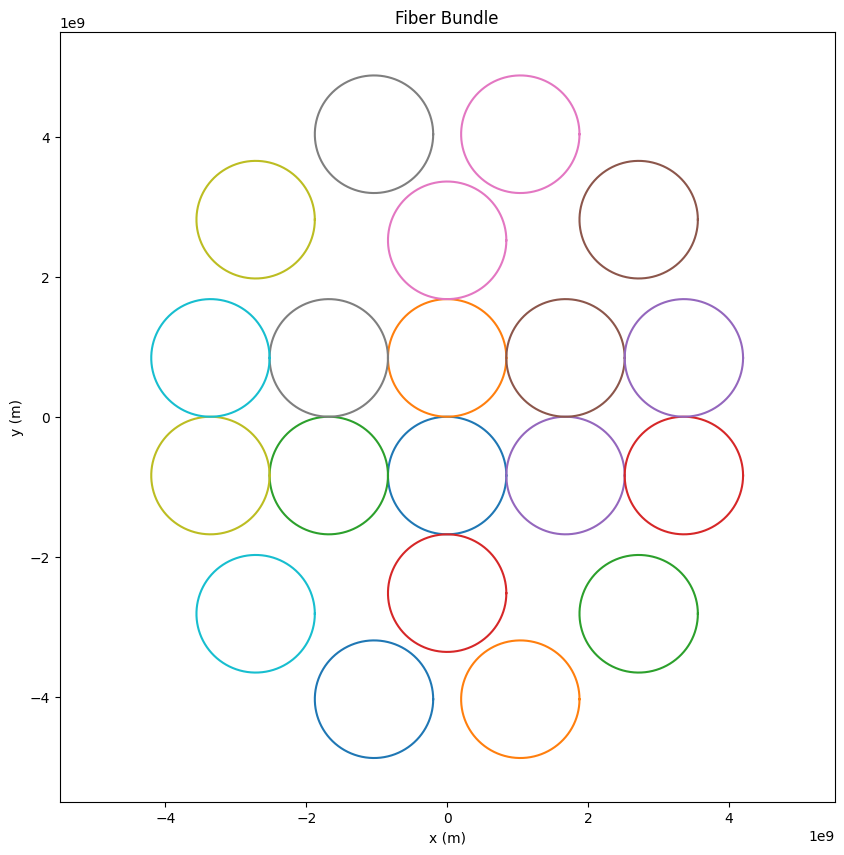

In [1]:
import fiber

b = fiber.FiberBundle(r = 5e-3 * 1e12, core = 200e-6 * 2 * 1e12, cladding = 220e-6 * 2 * 1e12)
b.plot()

Below, I'm making the representation of the two plastic fiber halves. I have made an adjustable gap in the middle, and I've found a method to check if a laser point lies in one of the halves of the bundle.

False
True


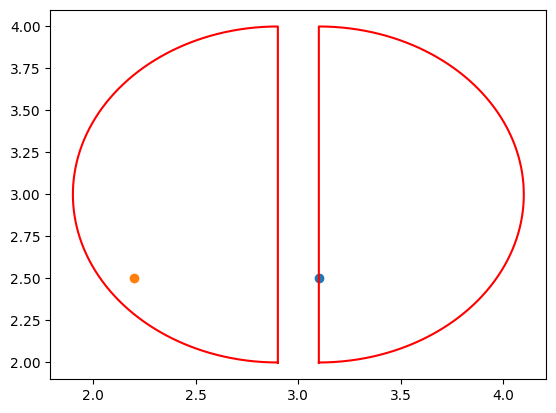

In [46]:
import numpy as np
import matplotlib.pyplot as plt

r = 1
line = 0.1
c = [3, 3]
l = [3.1, 2.5]
x = np.append(np.full(100, c[0] + line), r * np.sin(np.linspace(0, 1, 1000) * np.pi) + line + c[0])
y = np.append(np.linspace(-(r - c[1]), (r + c[1]), 100), r * np.cos(np.linspace(0, 1, 1000) * np.pi) + c[1])
plt.plot(x, y, c = "r")
x = np.append(np.full(100, c[0] - line), r * np.sin(-np.linspace(0, 1, 1000) * np.pi) - line + c[0])
y = np.append(np.linspace(-(r - c[1]), (r + c[1]), 100), r * np.cos(np.linspace(0, 1, 1000) * np.pi) + c[1])
plt.plot(x, y, c = "r")
# plt.plot(r * np.sin(-x * np.pi) - line + c[0], r * np.cos(y * np.pi) + c[1], c = "b")
# plt.vlines([line + c[0], -line + c[0]], -(r - c[1]), (r + c[1]), color = "k")
plt.scatter(l[0], l[1])
neg = 2.2
plt.scatter(neg, l[1])

print((l[0] - c[0] - line) ** 2 + (l[1] - c[1]) ** 2 < (r) ** 2 and l[0] > c[0] + line)
print((neg - c[0] + line) ** 2 + (l[1] - c[1]) ** 2 < (r) ** 2 and neg < c[0] - line)

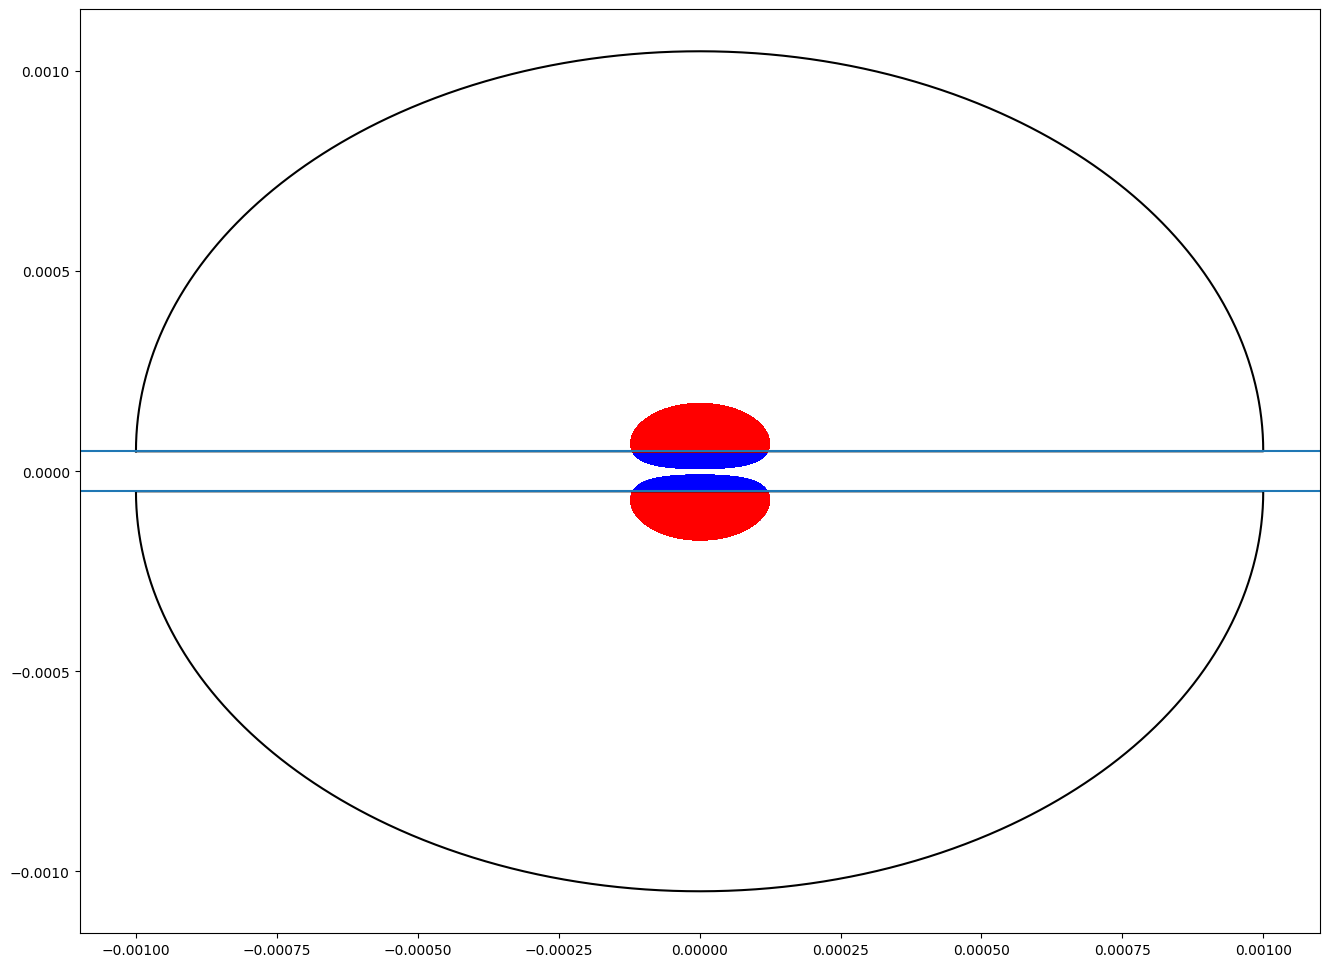

57.508017842542785


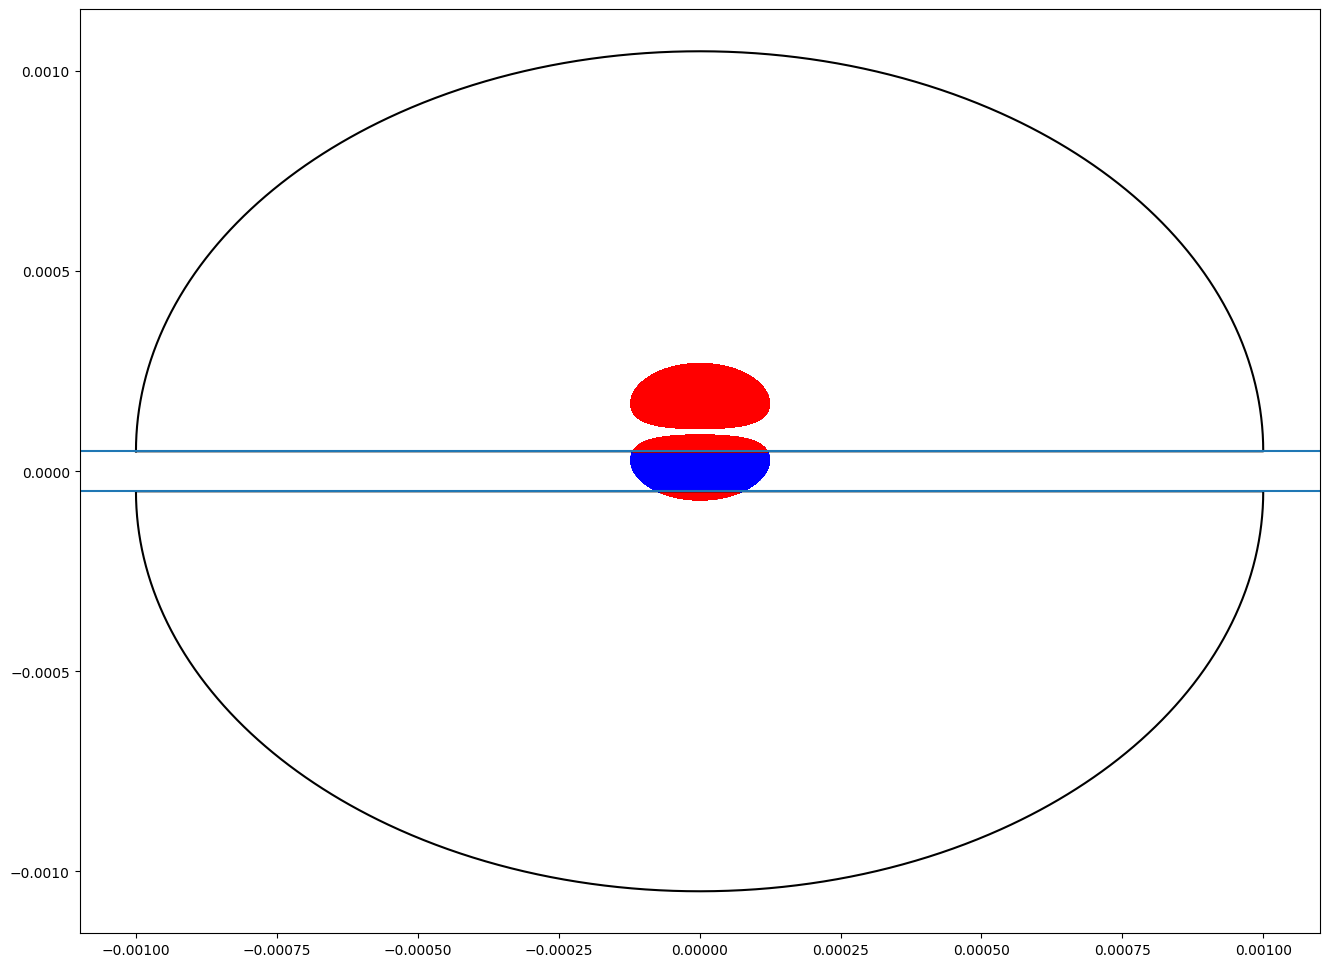

In [10]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
import jax
import laser
from jax import jit
jax.config.update("jax_enable_x64", True)

class plasticbundle:
    def __init__(self, r, gap, center = [0, 0], res = 1000, orientation = "v"):
        self.r = r
        self.gap = gap
        self.res = res
        self.center = center
        self.orientation = orientation
        self.halves = self.draw_bundle(r, gap, res, center, orientation)
        return
    
    @staticmethod
    @jit(static_argnames=["res", "orientation"])
    def draw_bundle(r, gap, res, center, orientation):
        if orientation.upper() == "v".upper():
            f1 = jnp.array([jnp.append(jnp.full(100, center[0] + gap / 2), r * jnp.sin(jnp.linspace(0, 1, res - 100) * jnp.pi) + gap / 2 + center[0]), jnp.append(jnp.linspace(-(r - center[1]), (r + center[1]), 100), r * jnp.cos(jnp.linspace(0, 1, res - 100) * jnp.pi) + center[1])])
            f2 = jnp.array([jnp.append(jnp.full(100, center[0] - gap / 2), r * jnp.sin(-jnp.linspace(0, 1, res - 100) * jnp.pi) - gap / 2 + center[0]), jnp.append(jnp.linspace(-(r - center[1]), (r + center[1]), 100), r * jnp.cos(jnp.linspace(0, 1, res - 100) * jnp.pi) + center[1])])
        else:
            f1 = jnp.array([jnp.append(jnp.linspace(-(r - center[0]), (r + center[0]), 100), r * jnp.cos(jnp.linspace(0, 1, res - 100) * jnp.pi) + center[0]), jnp.append(jnp.full(100, center[1] + gap / 2), r * jnp.sin(jnp.linspace(0, 1, res - 100) * jnp.pi) + gap / 2 + center[1])])
            f2 = jnp.array([jnp.append(jnp.linspace(-(r - center[0]), (r + center[0]), 100), r * jnp.cos(jnp.linspace(0, 1, res - 100) * jnp.pi) + center[0]), jnp.append(jnp.full(100, center[1] - gap / 2), r * jnp.sin(-jnp.linspace(0, 1, res - 100) * jnp.pi) - gap / 2 + center[1])])
        return jnp.array([f1, f2])
    
    def plot(self, ax = None, figsize = (8, 6), im = [], c = "k"):
        import matplotlib.pyplot as plt
        plt.ioff()
        if ax == None:
            fig, ax = plt.subplots(1, 1, figsize = figsize)
        else:
            fig = plt.gcf()
        for h in self.halves:
            ax.plot(h[0], h[1], c = c)
        if len(im) > 0:
            ax.scatter(im.x[~jnp.isnan(im.P)], im.y[~jnp.isnan(im.P)], c = "b", s = 1)
        plt.ion()
        return fig, ax
    
    @jit(static_argnums=(0,2))
    def sum_power(self, l, half = -1):
        P = jnp.where(jnp.isnan(l.P), 0, l.P)
        if self.orientation.upper() == "v".upper():
            half1 = ((l.x - self.center[0] - self.gap / 2) ** 2 + (l.y - self.center[1]) ** 2 < self.r ** 2) & (l.x > self.center[0] + self.gap / 2)
            half2 = ((l.x - self.center[0] + self.gap / 2) ** 2 + (l.y - self.center[1]) ** 2 < self.r ** 2) & (l.x < self.center[0] - self.gap / 2)
        else:
            half1 = ((l.x - self.center[0]) ** 2 + (l.y - self.center[1] - self.gap / 2) ** 2 < self.r ** 2) & (l.y > self.center[1] + self.gap / 2)
            half2 = ((l.x - self.center[0]) ** 2 + (l.y - self.center[1] + self.gap / 2) ** 2 < self.r ** 2) & (l.y < self.center[1] - self.gap / 2)
            
        half1_P = jnp.sum(P * half1)
        half2_P = jnp.sum(P * half2)
        if half == 0:
            return half1_P
        elif half == 1:
            return half2_P
        else:
            return half1_P + half2_P
    @jit(static_argnums=0)
    def diff_power(self, l):
        return self.sum_power(l, 0) - self.sum_power(l, 1)

    def _tree_flatten(self):
        children = (self.halves,)
        aux = {
            "r": self.r, "gap": self.gap, "center": self.center, "res": self.res, "orientation": self.orientation
        }
        return (children, aux)
    @classmethod
    def _tree_unflatten(cls, aux, children):
        obj = cls.__new__(cls)
        obj.r = aux["r"]
        obj.gap = aux["gap"]
        obj.center = aux["center"]
        obj.res = aux["res"]
        obj.orientation = aux["orientation"]
        obj.halves = children
        return obj

jax.clear_caches()
l = jax.block_until_ready(laser.laser(0, 0, 0, waist = 1e-4, power = 102, res = 10000, mode = (0, 1), mode_type = 0, chop = True, chop_threshold = 1e-5))

fig, ax = plt.subplots(1, 1, figsize = (16, 12))
p = plasticbundle(1e-3, 1e-4, orientation = "h")
p.plot(ax, im = l)
ax.axhline(p.gap / 2)
ax.axhline(-p.gap / 2)
ax.scatter(l.x[((l.x - p.center[0]) ** 2 + (l.y - p.center[1] - p.gap / 2) ** 2 < p.r ** 2) & (l.y > p.center[1] + p.gap / 2) & ~jnp.isnan(l.P)], l.y[((l.x - p.center[0]) ** 2 + (l.y - p.center[1] - p.gap / 2) ** 2 < p.r ** 2) & (l.y > p.center[1] + p.gap / 2) & ~jnp.isnan(l.P)], c = "r", s = 1)
ax.scatter(l.x[((l.x - p.center[0]) ** 2 + (l.y - p.center[1] + p.gap / 2) ** 2 < p.r ** 2) & (l.y < p.center[1] - p.gap / 2) & ~jnp.isnan(l.P)], l.y[((l.x - p.center[0]) ** 2 + (l.y - p.center[1] + p.gap / 2) ** 2 < p.r ** 2) & (l.y < p.center[1] - p.gap / 2) & ~jnp.isnan(l.P)], c = "r", s = 1)
plt.show()
p1 = p.diff_power(l)
l = l.dy(1e-4)
p2 = p.diff_power(l)
print(p2 - p1)

fig, ax = plt.subplots(1, 1, figsize = (16, 12))
p.plot(ax, im = l)
ax.axhline(p.gap / 2)
ax.axhline(-p.gap / 2)
ax.scatter(l.x[((l.x - p.center[0]) ** 2 + (l.y - p.center[1] - p.gap / 2) ** 2 < p.r ** 2) & (l.y > p.center[1] + p.gap / 2) & ~jnp.isnan(l.P)], l.y[((l.x - p.center[0]) ** 2 + (l.y - p.center[1] - p.gap / 2) ** 2 < p.r ** 2) & (l.y > p.center[1] + p.gap / 2) & ~jnp.isnan(l.P)], c = "r", s = 1)
ax.scatter(l.x[((l.x - p.center[0]) ** 2 + (l.y - p.center[1] + p.gap / 2) ** 2 < p.r ** 2) & (l.y < p.center[1] - p.gap / 2) & ~jnp.isnan(l.P)], l.y[((l.x - p.center[0]) ** 2 + (l.y - p.center[1] + p.gap / 2) ** 2 < p.r ** 2) & (l.y < p.center[1] - p.gap / 2) & ~jnp.isnan(l.P)], c = "r", s = 1)
plt.show()

(<Figure size 1000x1000 with 1 Axes>, <Axes3D: >)

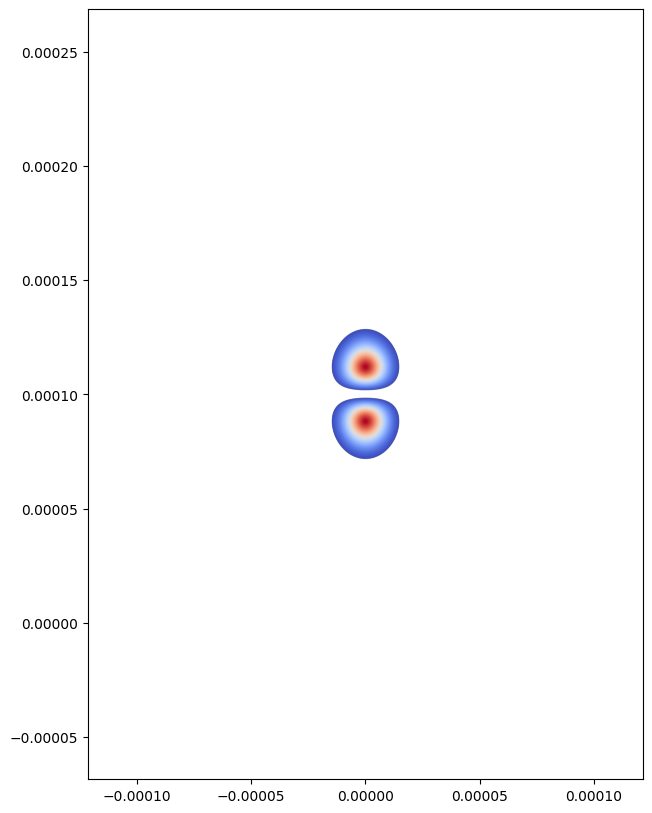

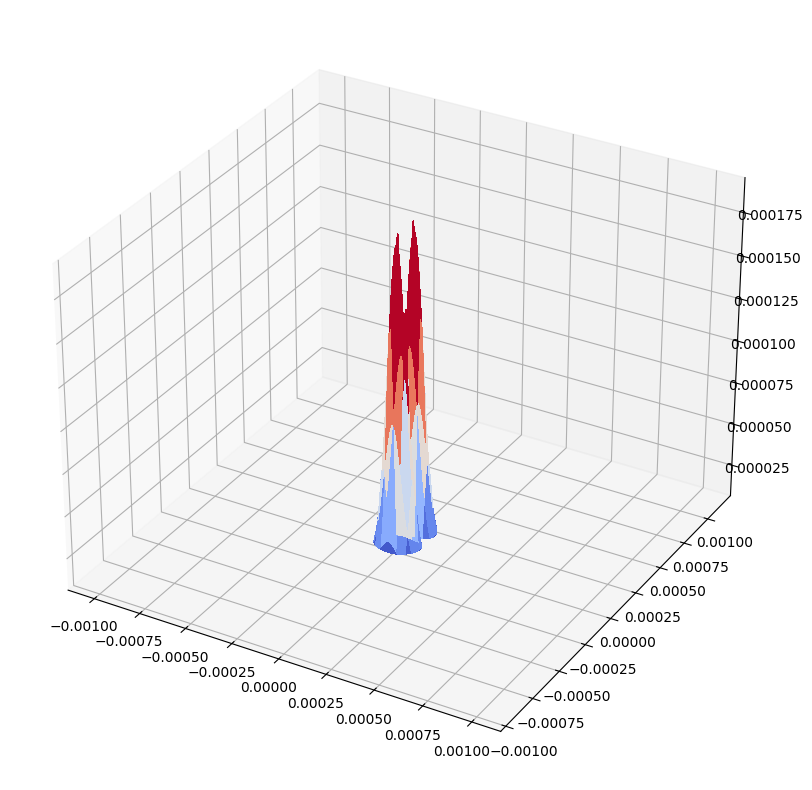

In [12]:
l.imshow()
l.plot_surface()

In [13]:
l = jax.block_until_ready(laser.laser(0, 0, 0, waist = 1e-4, power = 102, res = 10000, mode = (0, 1), mode_type = 0, chop = False, chop_threshold = 1e-5))

(<Figure size 1000x1000 with 1 Axes>, <Axes: >)

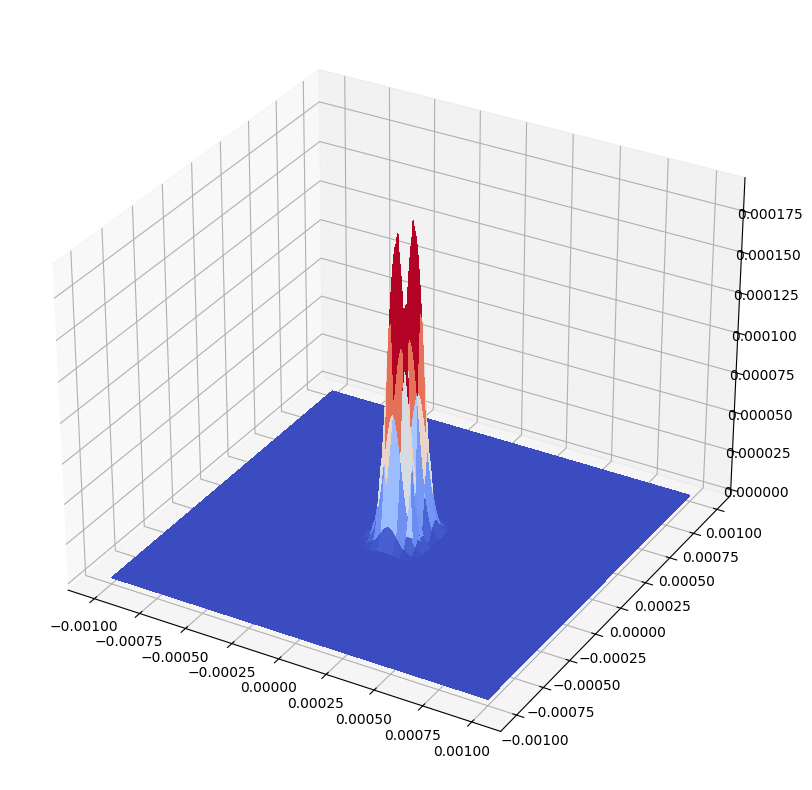

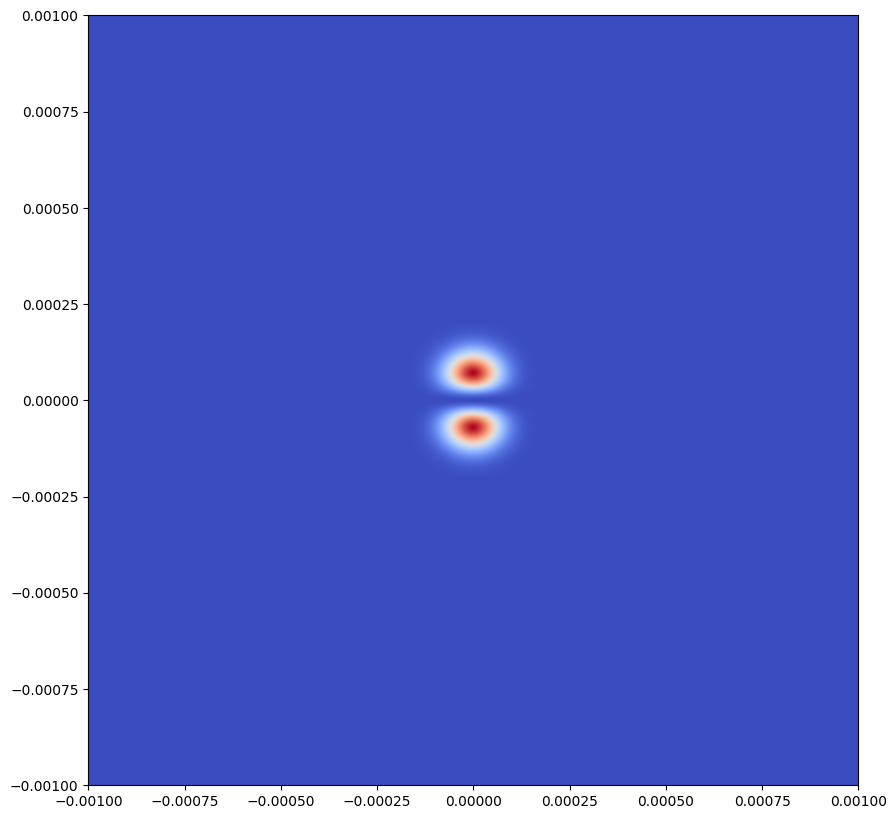

In [15]:
l.plot_surface()
l.imshow()

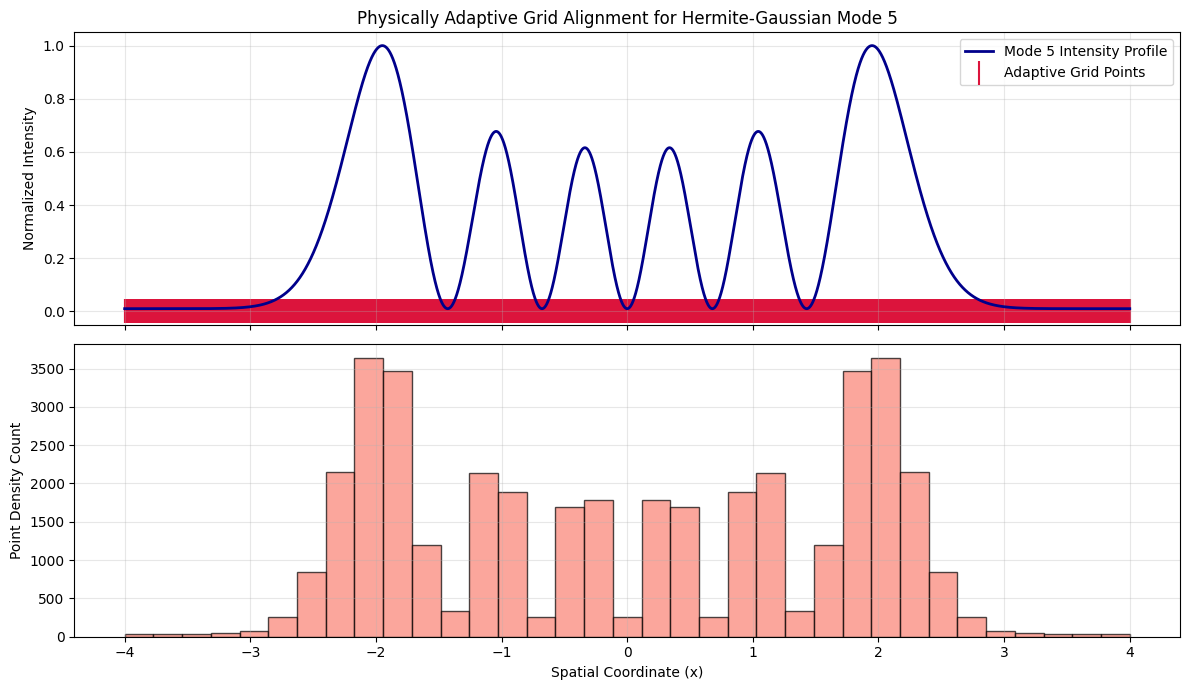

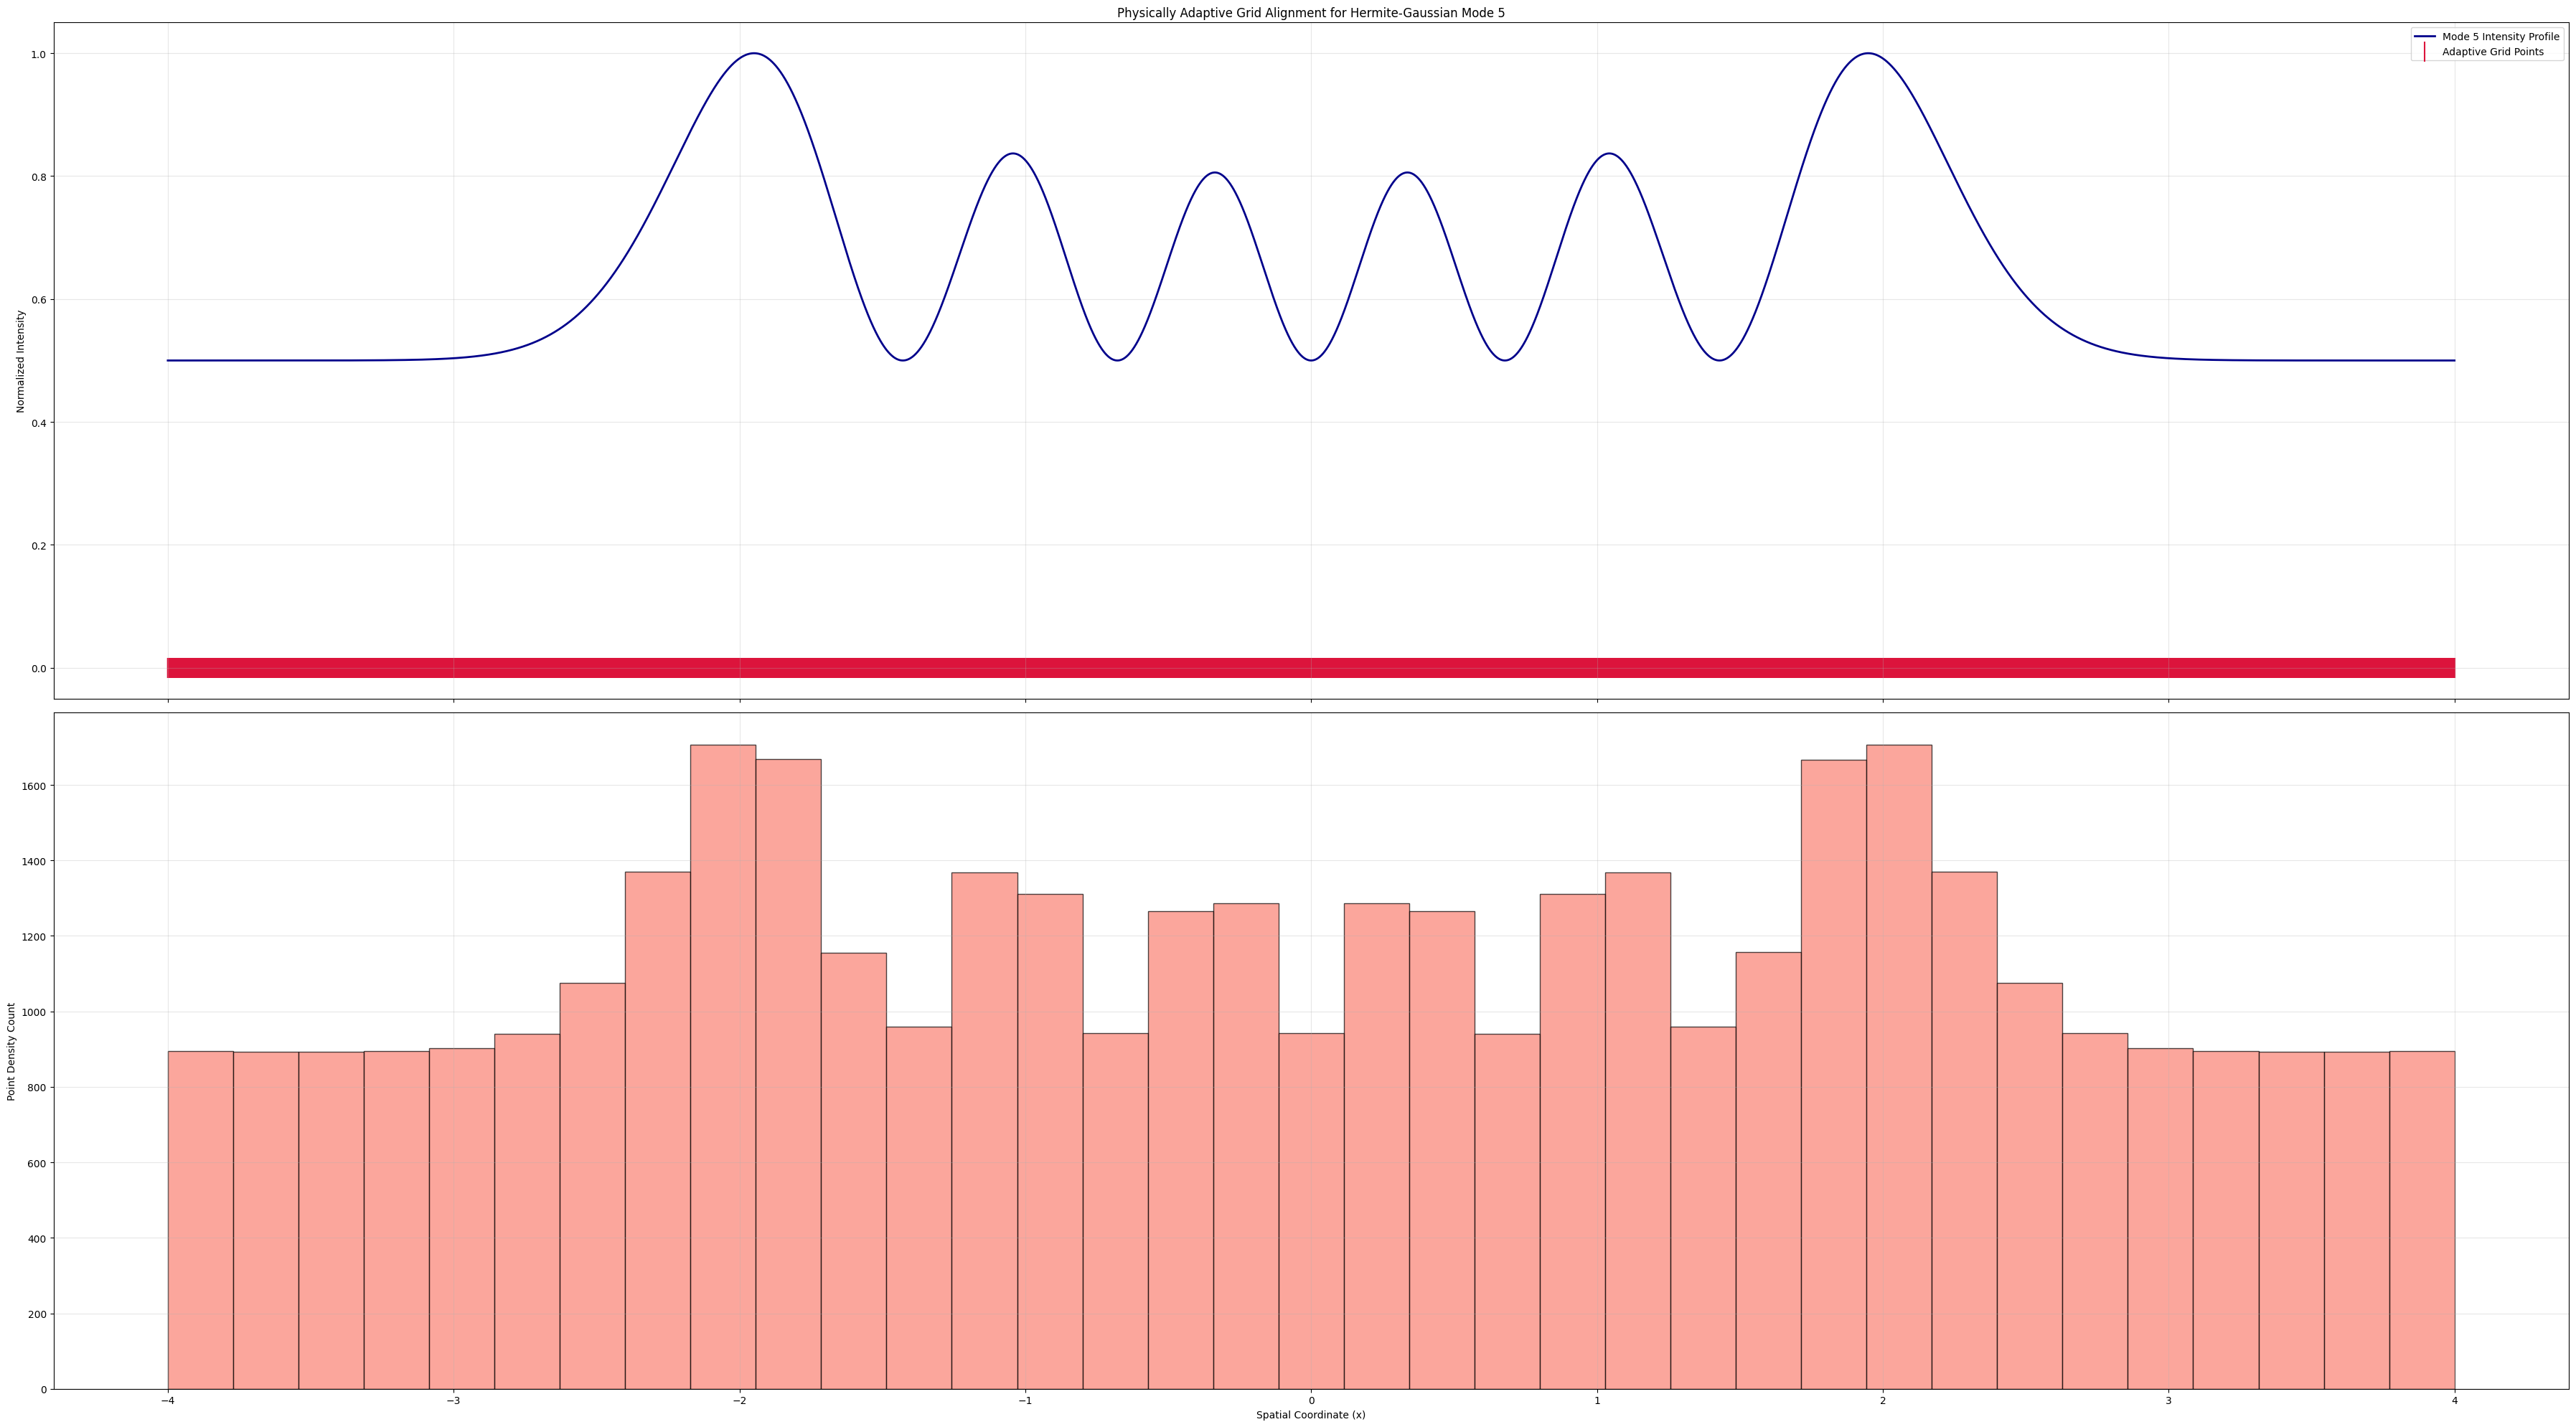

In [12]:
import pandas as pd
import jax.numpy as jnp
import matplotlib.pyplot as plt
import jax
import laser
from jax import jit
import plasticbundle as pbndl

def make_adaptive_linspace(start, stop, res, mode_num, w=1.0):
    """
    Generates a 1D grid of 'res' points whose density is proportional 
    to the intensity of the specified Hermite-Gaussian mode.
    """
    # 1. Generate a fine background mesh to accurately resolve the polynomial peaks
    fine_res = res * 10
    x_fine = jnp.linspace(start, stop, fine_res)
    
    # 2. Calculate the physical intensity profile I(x) = |E(x)|^2
    # (Using the Hermite math from your laser script)
    E_field = laser.jax_hermite(mode_num, jnp.sqrt(2) * x_fine / w) * jnp.exp(-x_fine**2 / w**2)
    intensity = E_field ** 2
    
    # Add a tiny baseline floor (e.g., 5% of peak) so the edges don't become completely empty
    intensity = intensity + 0.01 * jnp.max(intensity)
    
    # 3. Compute the numerical Cumulative Distribution Function (CDF)
    # dx is the spacing between fine mesh points
    dx = (stop - start) / (fine_res - 1)
    cdf = jnp.cumsum(intensity) * dx
    cdf_normalized = cdf / cdf[-1]  # Force scale strictly from 0.0 to 1.0
    
    # 4. Inverse Transform Sampling
    # Map a perfectly uniform target grid through the inverted CDF
    uniform_target = jnp.linspace(0.0, 1.0, res)
    
    # jnp.interp(target_y, current_y, current_x) acts as our inverse function
    adaptive_x = jnp.interp(uniform_target, cdf_normalized, x_fine)
    
    return adaptive_x, x_fine, intensity / jnp.max(intensity)

# --- Test with a High-Order Mode (e.g., Mode n=4) ---
start, stop, res = -4.0, 4.0, 40000
mode_n = 5

x_adaptive, x_fine, norm_intensity = make_adaptive_linspace(start, stop, res, mode_n, w=1.0)

# --- Visualization ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Top Plot: Intensity Profile vs actual point locations
ax1.plot(x_fine, norm_intensity, color='darkblue', linewidth=2, label=f"Mode {mode_n} Intensity Profile")
ax1.scatter(x_adaptive, jnp.zeros_like(x_adaptive), color='crimson', marker='|', s=300, label="Adaptive Grid Points")
ax1.set_title(f"Physically Adaptive Grid Alignment for Hermite-Gaussian Mode {mode_n}")
ax1.set_ylabel("Normalized Intensity")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Bottom Plot: Histogram verifying the structural point tracking
ax2.hist(x_adaptive, bins=35, edgecolor='black', color='salmon', alpha=0.7)
ax2.set_ylabel("Point Density Count")
ax2.set_xlabel("Spatial Coordinate (x)")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

def make_adaptive_linspace(start, stop, res, mode_num, w=1.0):
    """
    Generates a 1D grid of 'res' points whose density is proportional 
    to the intensity of the specified Hermite-Gaussian mode.
    """
    # 1. Generate a fine background mesh to accurately resolve the polynomial peaks
    fine_res = res * 10
    x_fine = jnp.linspace(start, stop, fine_res)
    
    # 2. Calculate the physical intensity profile I(x) = |E(x)|^2
    # (Using the Hermite math from your laser script)
    E_field = laser.jax_hermite(mode_num, jnp.sqrt(2) * x_fine / w) * jnp.exp(-x_fine**2 / w**2)
    intensity = E_field ** 2
    
    # Add a tiny baseline floor (e.g., 5% of peak) so the edges don't become completely empty
    intensity = intensity + 1 * jnp.max(intensity)
    
    # 3. Compute the numerical Cumulative Distribution Function (CDF)
    # dx is the spacing between fine mesh points
    dx = (stop - start) / (fine_res - 1)
    cdf = jnp.cumsum(intensity) * dx
    cdf_normalized = cdf / cdf[-1]  # Force scale strictly from 0.0 to 1.0
    
    # 4. Inverse Transform Sampling
    # Map a perfectly uniform target grid through the inverted CDF
    uniform_target = jnp.linspace(0.0, 1.0, res)
    
    # jnp.interp(target_y, current_y, current_x) acts as our inverse function
    adaptive_x = jnp.interp(uniform_target, cdf_normalized, x_fine)
    
    return adaptive_x, x_fine, intensity / jnp.max(intensity)

# --- Test with a High-Order Mode (e.g., Mode n=4) ---
start, stop, res = -4.0, 4.0, 40000
mode_n = 5

x_adaptive, x_fine, norm_intensity = make_adaptive_linspace(start, stop, res, mode_n, w=1.0)

# --- Visualization ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(36, 20), sharex=True)

# Top Plot: Intensity Profile vs actual point locations
ax1.plot(x_fine, norm_intensity, color='darkblue', linewidth=2, label=f"Mode {mode_n} Intensity Profile")
ax1.scatter(x_adaptive, jnp.zeros_like(x_adaptive), color='crimson', marker='|', s=400, label="Adaptive Grid Points")
ax1.set_title(f"Physically Adaptive Grid Alignment for Hermite-Gaussian Mode {mode_n}")
ax1.set_ylabel("Normalized Intensity")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Bottom Plot: Histogram verifying the structural point tracking
ax2.hist(x_adaptive, bins=35, edgecolor='black', color='salmon', alpha=0.7)
ax2.set_ylabel("Point Density Count")
ax2.set_xlabel("Spatial Coordinate (x)")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

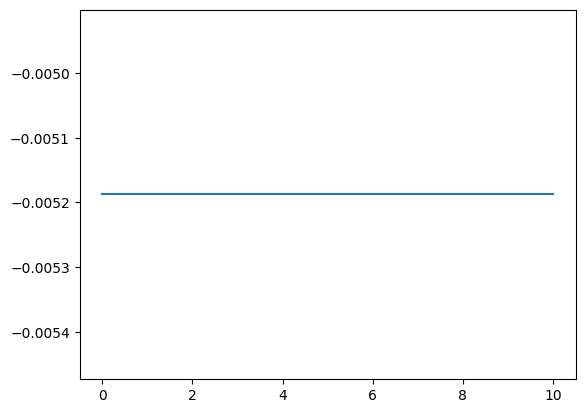

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("test_data2.csv")
plt.plot(df["t"], df["voltage"])

(<Figure size 1000x1000 with 1 Axes>, <Axes: >)

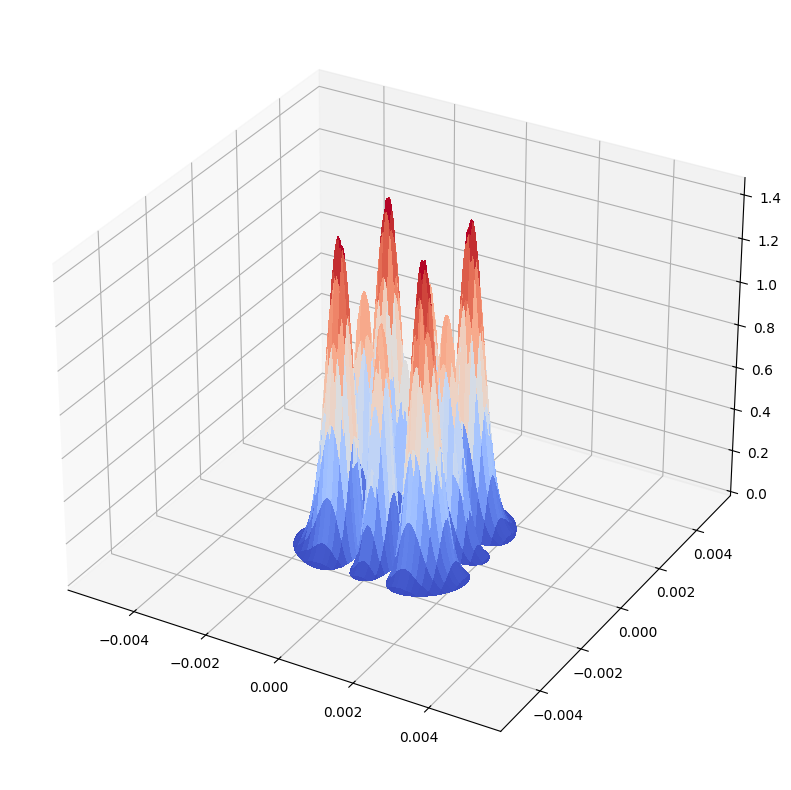

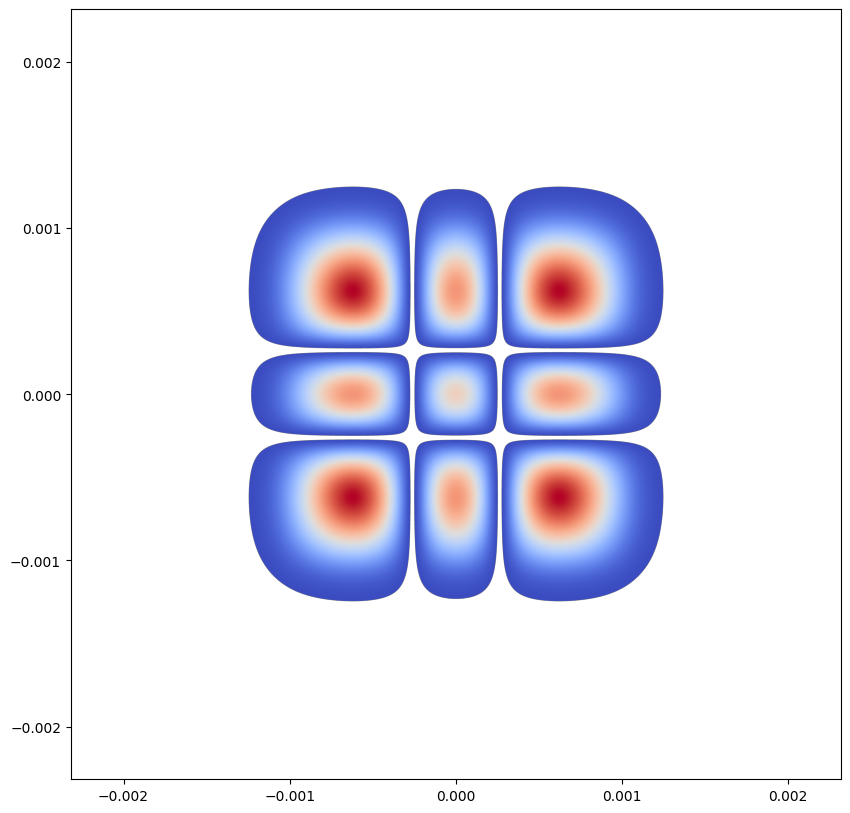

In [3]:
import laser
import jax 
import matplotlib.pyplot as plt
import jax.numpy as jnp

l = jax.block_until_ready(laser.laser(0, 0, 0, waist = 1e-3, power = 102, res = 10000, mode = [2, 2], mode_type = 0, chop = True, chop_threshold = 1e-7, density = 1))
l.plot_surface()
l.imshow()
# def adaptive_laguerre_linspace(waist, res, mode, w = 1):
#     mult = (3 + jnp.sqrt(jnp.max(jnp.array(mode))) * 1.5)
#     r = jnp.sqrt(2) * jnp.linspace(0, mult * waist, res)
#     A = (2 * r ** 2 / w ** 2) ** mode[1]
#     I = A * laser.jax_genlaguerre(mode[0], mode[1], 2 * r ** 2 / w ** 2) ** 2 * jnp.cos(mode[1]) ** 2 * jnp.exp(-2 * r ** 2 / w ** 2)
#     I = I + 0.05 * jnp.max(I)

#     dr = (waist * mult) / (res - 1)
#     cdf = jnp.cumsum(I) * dr
#     cdf = cdf / cdf[-1]

#     targ = jnp.linspace(0, 1, res // 2)
#     half = jnp.interp(targ, cdf, r)

#     lin = jnp.concatenate([-half[::-1], half])
#     if res % 2 != 0:
#         lin = jnp.insert(lin, half, 0)
#     return lin
# r = adaptive_laguerre_linspace(1e-3, 10000, [0, 0])
# R = jnp.sqrt(r[jnp.newaxis, :] ** 2 + r[:, jnp.newaxis] ** 2)
# plt.scatter(r, jnp.zeros_like(r), color='crimson', marker='|', s=300, label="Adaptive Grid Points")
# plt.hist(R, bins = "auto")
# plt.title(f"Physically Adaptive Grid Alignment for Hermite-Gaussian Mode")
# plt.ylabel("Normalized Intensity")
# plt.legend()
# plt.grid(True, alpha=0.3)
# fig = plt.figure(figsize = (8, 6))
# ax = fig.add_subplot(111, projection='3d')
# ax.plot_surface(r, r, (2 * R ** 2 / 1 ** 2) * laser.jax_genlaguerre(0, 0, 2 * R ** 2 / 1 ** 2) ** 2 * jnp.exp(-2 * R ** 2 / 1 ** 2))

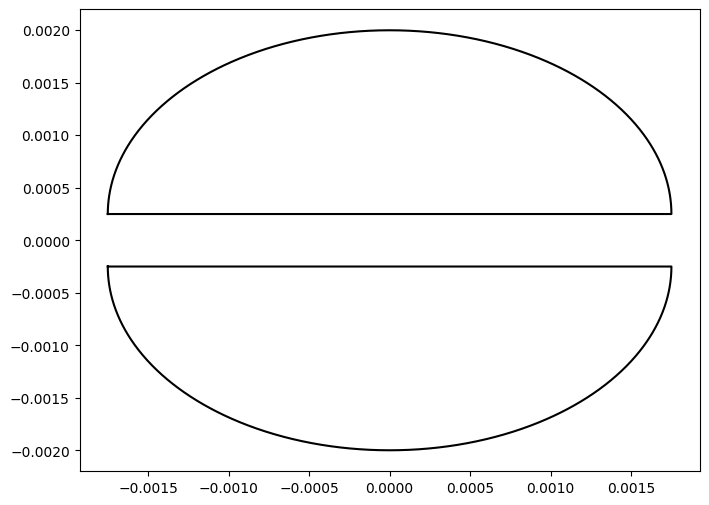

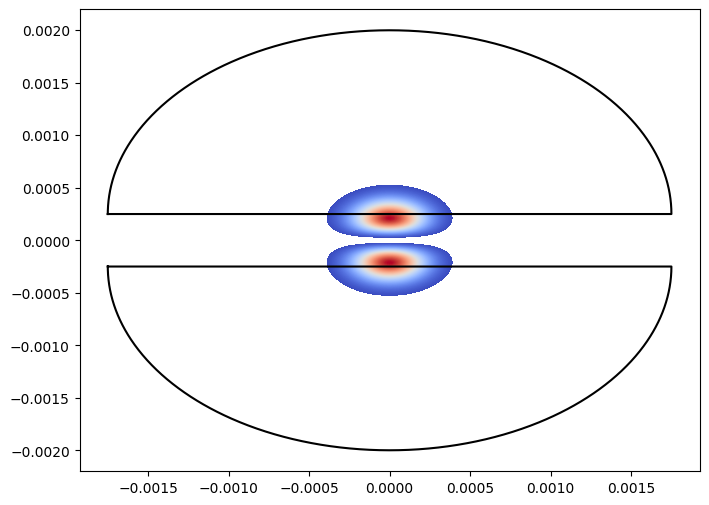

Bad pipe message: %s [b'X\x10x&\xa5\xb4\x03\x08\xbbZ\x97\x7f\xc5\xd9\x82\x19\xa4;\x00\x01|\x00\x00\x00\x01\x00\x02\x00\x03\x00\x04\x00\x05\x00\x06\x00\x07\x00\x08\x00\t\x00\n\x00\x0b\x00\x0c\x00\r\x00\x0e\x00\x0f\x00\x10\x00\x11\x00\x12\x00\x13\x00\x14\x00\x15\x00\x16\x00\x17\x00\x18\x00\x19\x00\x1a\x00\x1b\x00/\x000\x001\x002\x003\x004\x005\x006\x007\x008\x009\x00:\x00;\x00<\x00=\x00>\x00?\x00@\x00A\x00B\x00C\x00D\x00E\x00F\x00g\x00h\x00i\x00j\x00k\x00l\x00m\x00\x84\x00\x85\x00\x86\x00\x87\x00\x88\x00\x89\x00\x96\x00\x97\x00\x98\x00\x99\x00\x9a\x00\x9b\x00\x9c\x00\x9d\x00\x9e\x00\x9f\x00\xa0\x00\xa1\x00\xa2\x00\xa3\x00\xa4\x00\xa5\x00\xa6\x00\xa7\x00\xba\x00\xbb\x00\xbc\x00\xbd\x00\xbe\x00\xbf\x00\xc0\x00\xc1\x00\xc2\x00\xc3\x00\xc4\x00\xc5\x13\x01']
Bad pipe message: %s [b'\x13\x03\x13\x04\x13\x05\xc0\x01\xc0\x02\xc0\x03\xc0\x04\xc0\x05\xc0\x06']
Bad pipe message: %s [b"\xc0\x08\xc0\t\xc0\n\xc0\x0b\xc0\x0c\xc0\r\xc0\x0e\xc0\x0f\xc0\x10\xc0\x11\xc0\x12\xc0\x13\xc0\x14\xc0\x15\xc0\x16\

In [3]:
import plasticbundle as pbndl
from matplotlib import cm
import laser
import matplotlib.pyplot as plt
import jax

l = jax.block_until_ready(laser.laser(0, 0, 0, waist = 0.5e-3 * 0.6, power = 102, res = 10000, mode = [0, 1], mode_type = 0, chop = True, chop_threshold = 1e-7))
b = jax.block_until_ready(pbndl.plasticbundle(3.5e-3 / 2, .5e-3, orientation = "h"))
fig, ax = b.plot()
ax.pcolormesh(l.x, l.y, l.P, cmap = cm.coolwarm)
plt.show()

In [18]:
import plasticbundle as pbndl
from matplotlib import cm
import jax
import jax.numpy as jnp

jax.clear_caches()
b = jax.block_until_ready(pbndl.plasticbundle(3.5e-3 / 2, .5e-3, orientation = "h"))
dens = jnp.linspace(1, 0, 1000, dtype = jnp.float64, endpoint = False)[::-1]
for i in dens:
    jax.clear_caches()
    l = jax.block_until_ready(laser.laser(0, 0, 0, waist = 1e-3, power = 102, res = 40000, mode = [0, 0], mode_type = 0, chop = True, chop_threshold = 1e-7, density = i))
    o = b.diff_power(l)
    l = l.dy(0.44e-9)
    s = b.diff_power(l)
    if o - s != 0:
        print(f"works at {i}")

E0710 14:48:42.280669    5535 gpu_hlo_schedule.cc:968] The byte size of input/output arguments (25601280032) exceeds the base limit (12820856832). This indicates an error in the calculation!
W0710 14:48:42.280995    5535 hlo_rematerialization.cc:3231] Can't reduce memory use below 11.92GiB (12800640024 bytes) by rematerialization; only reduced to 11.92GiB (12800640048 bytes), down from 11.92GiB (12800640048 bytes) originally
E0710 14:48:43.919012    5535 gpu_hlo_schedule.cc:968] The byte size of input/output arguments (25601280032) exceeds the base limit (12820856832). This indicates an error in the calculation!
W0710 14:48:43.919234    5535 hlo_rematerialization.cc:3231] Can't reduce memory use below 11.92GiB (12800640024 bytes) by rematerialization; only reduced to 11.92GiB (12800640048 bytes), down from 11.92GiB (12800640048 bytes) originally
E0710 14:48:45.544244    5535 gpu_hlo_schedule.cc:968] The byte size of input/output arguments (25601280032) exceeds the base limit (128208568

KeyboardInterrupt: 

Bad pipe message: %s [b'S\x18\x84z\x85\r\xe3\xca~\x90\xb1J\x8d\x9bn2\x94M\x00\x01|\x00\x00\x00\x01\x00\x02\x00\x03\x00\x04\x00\x05\x00\x06\x00\x07\x00\x08\x00\t\x00\n\x00\x0b\x00\x0c\x00\r\x00\x0e\x00\x0f\x00\x10\x00\x11\x00\x12\x00\x13\x00\x14\x00\x15\x00\x16\x00\x17\x00\x18\x00\x19\x00\x1a\x00\x1b\x00/\x000\x001\x002\x003\x004\x005\x006\x007\x008\x009\x00:\x00;\x00<\x00=\x00>\x00?\x00@\x00A\x00B\x00C\x00D\x00E\x00F\x00g\x00h\x00i\x00j\x00k\x00l\x00m\x00\x84\x00\x85\x00\x86\x00\x87\x00\x88\x00\x89\x00\x96\x00\x97\x00\x98\x00\x99\x00\x9a\x00\x9b\x00\x9c\x00\x9d\x00\x9e']
Bad pipe message: %s [b':\x13]6E\xffL\x9f\xc0c\xaf\xf4\\\xaf\x1d,\x1f:\x00\x01|\x00\x00\x00\x01\x00\x02\x00\x03\x00\x04\x00\x05\x00\x06\x00\x07\x00\x08\x00\t\x00\n\x00\x0b\x00\x0c\x00\r\x00\x0e\x00\x0f\x00\x10\x00\x11\x00\x12\x00\x13\x00\x14\x00\x15\x00\x16\x00\x17\x00\x18\x00\x19\x00\x1a\x00\x1b\x00/\x000\x001\x002\x003\x004\x005\x006\x007\x008\x009\x00:\x00;\x00<\x00=\x00>\x00?\x00@\x00A\x00B\x00C\x00D\x00E\x00F\x00g

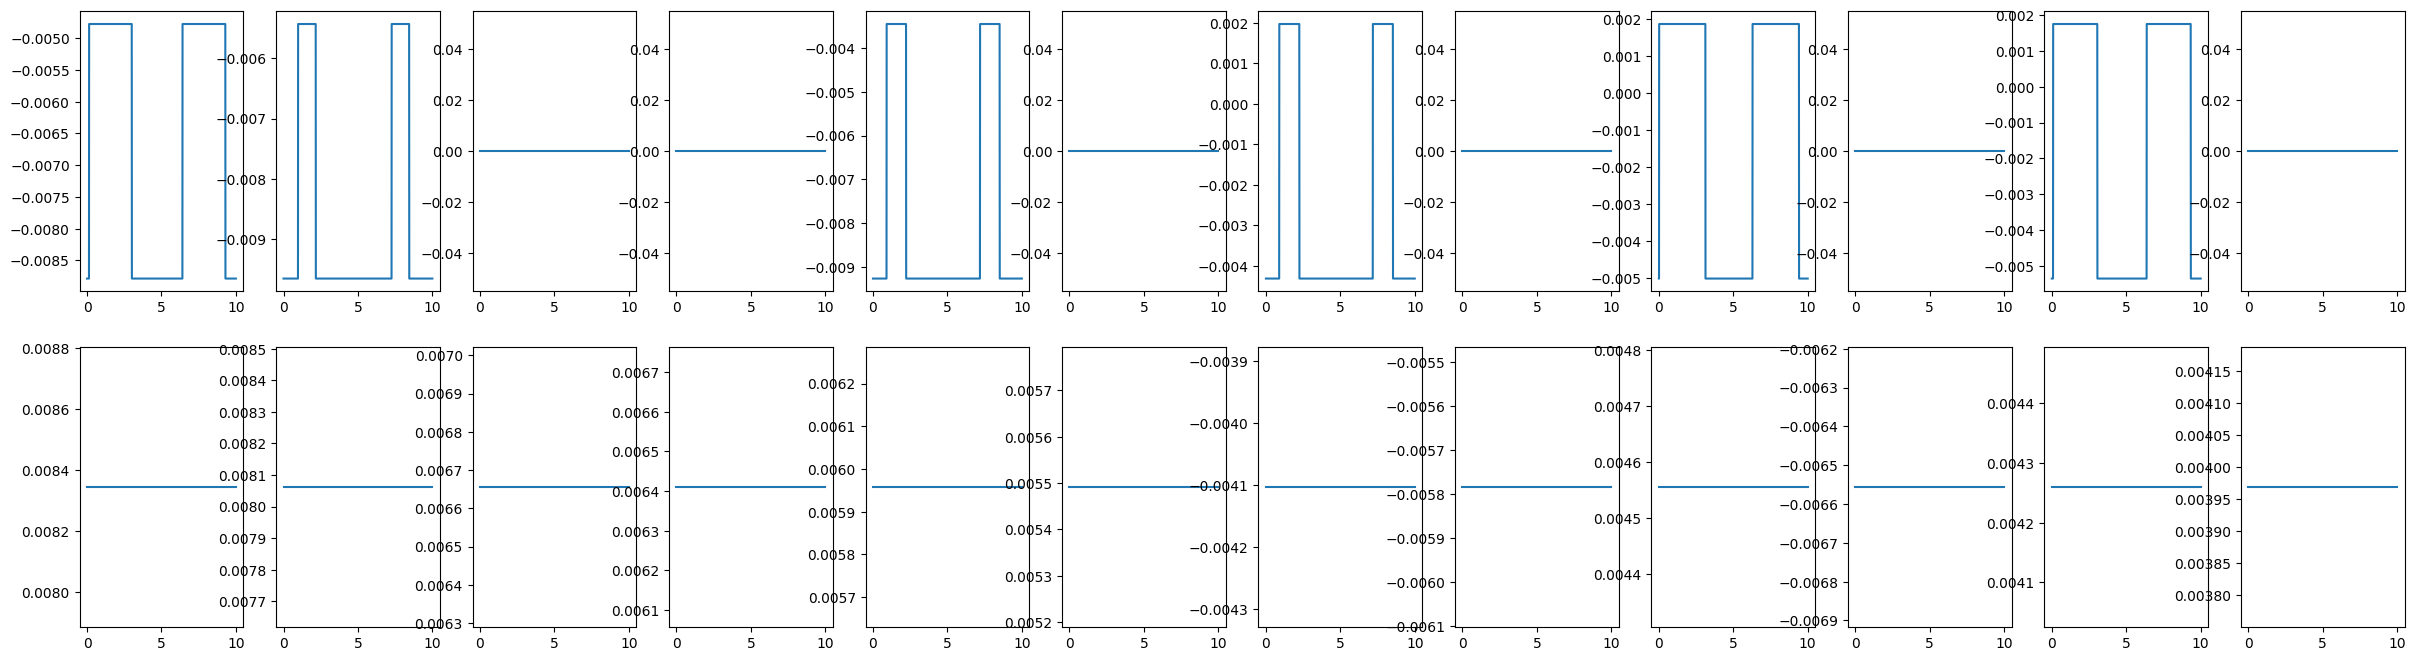

Bad pipe message: %s [b'\x1f\xb82\xafb\x93b\x92\xee0"J\xf3\x9c\\R\x97d\x00\x01|\x00\x00\x00\x01\x00\x02\x00\x03\x00\x04\x00\x05\x00\x06\x00\x07\x00\x08\x00\t\x00\n\x00\x0b\x00\x0c\x00\r\x00\x0e\x00\x0f\x00\x10\x00\x11\x00\x12\x00\x13\x00\x14\x00\x15\x00\x16\x00\x17\x00\x18\x00\x19\x00\x1a\x00\x1b\x00/\x000\x001\x002\x003\x004\x005\x006\x007\x008\x009\x00:\x00;\x00<\x00=\x00>\x00?\x00@\x00A\x00B\x00C\x00D\x00E\x00F\x00g\x00h\x00i\x00j\x00k\x00l\x00m\x00\x84\x00\x85\x00\x86\x00\x87\x00\x88\x00\x89\x00\x96\x00\x97\x00\x98\x00\x99\x00\x9a\x00\x9b\x00\x9c\x00\x9d\x00\x9e\x00\x9f\x00\xa0\x00\xa1\x00\xa2\x00\xa3\x00\xa4']
Bad pipe message: %s [b'\x00/4\xfb\x14\x84 \x9e\xcf\xda.\xdaP\xd6\xe7\x07:H\x00\x01|\x00\x00\x00\x01\x00\x02\x00\x03\x00\x04\x00\x05\x00\x06\x00\x07\x00\x08\x00\t\x00\n\x00\x0b\x00\x0c\x00\r\x00\x0e\x00\x0f\x00\x10\x00\x11\x00\x12\x00\x13\x00\x14\x00\x15\x00\x16\x00\x17\x00\x18\x00\x19\x00\x1a\x00\x1b\x00/\x000\x001\x002\x003\x004\x005\x006\x007\x008\x009\x00:\x00;\x00<\x00=

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
dens = [0.08599999999999997, 0.11199999999999999, 0.253, 0.30599999999999994, 0.376, 0.45899999999999996, 0.488, 0.6519999999999999, 0.6719999999999999, 0.745, 0.757, 0.852]
fig, ax = plt.subplots(2, 12, figsize = [30, 8])
for i, d in enumerate(dens):
    df = pd.read_csv(f"data/20260714/mode0-0_dens{d:.2f}.csv",)
    ax[0][i].plot(df["t"], df["voltage"])
for i, d in enumerate(dens):
    df = pd.read_csv(f"data/20260714/mode0-1_dens{d:.2f}.csv",)
    ax[1][i].plot(df["t"], df["voltage"])
plt.show()